In [1]:
import sys
sys.path.append("../")
from collections import defaultdict

import pyarrow.feather as feather
import numpy as np
import itertools
from pathlib import Path
from utils import *
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

from tqdm.auto import tqdm

import seaborn as sns
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

/Users/charlesdupont/Documents/code/deepfake-percolation/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_DIR = Path("../data/burnin_diagnostic/")

snap_df = feather.read_feather(DATA_DIR / "burnin_snapshots.arrow")
casc_df = feather.read_feather(DATA_DIR / "burnin_cascades.arrow")

cfg = {}
with open(DATA_DIR / "diagnostic_config.txt") as f:
    for line in f:
        k, v = line.strip().split(" = ")
        try:    cfg[k] = float(v)
        except: cfg[k] = v

BURN_IN   = int(cfg["burn_in_length"])
TRUE_PREV = 1.0 - cfg["p_fake"]
TRUE_TPR  = cfg["tpr"]
TRUE_FPR  = cfg["fpr"]

PARAM_STR = (f"v_cost={cfg['v_cost']}  loss={cfg['rep_loss']}  "
             f"tpr={cfg['tpr']}  fpr={cfg['fpr']}  p_fake={cfg['p_fake']}")

print(f"Reps        : {snap_df['rep_id'].nunique()}")
print(f"Timepoints  : {snap_df['cascade_id'].nunique()}")
print(f"Burn-in     : {BURN_IN} cascades")
print(f"Parameters: " + PARAM_STR)

Reps        : 50
Timepoints  : 2200
Burn-in     : 2000 cascades
Parameters: v_cost=0.01  loss=3.0  tpr=0.85  fpr=0.1  p_fake=0.2


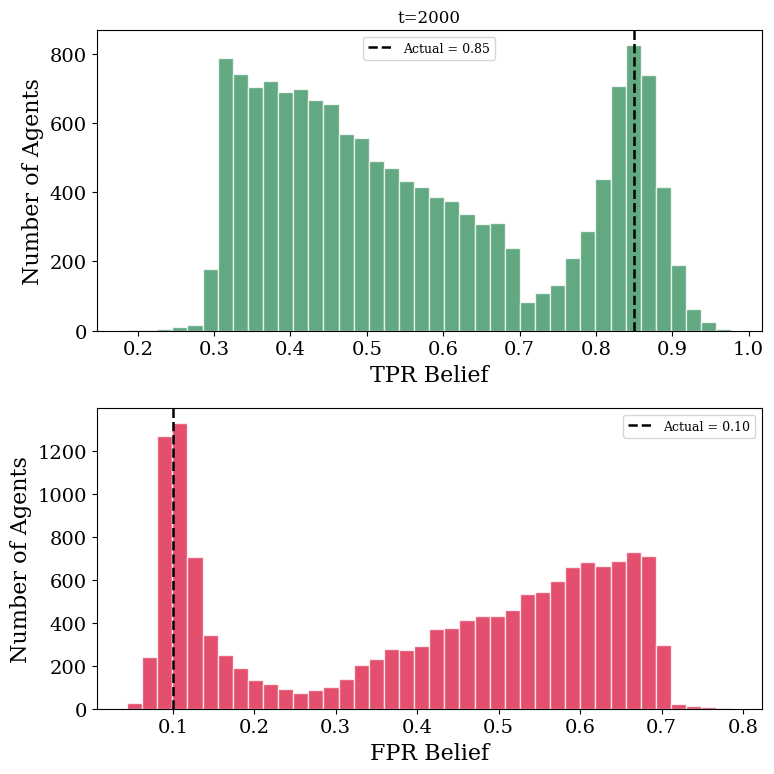

In [3]:
all_cids        = sorted(snap_df["cascade_id"].unique())
t_burnin_actual = min(all_cids, key=lambda x: abs(x - BURN_IN))
timepoints      = [t_burnin_actual]
t_labels        = {t_burnin_actual: f"t={t_burnin_actual}"}

dist_panels = [
    ("tpr_mean",  "Number of Agents", TRUE_TPR,  "seagreen", "TPR Belief"),
    ("fpr_mean",  "Number of Agents", TRUE_FPR,  "crimson", "FPR Belief"),
]

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey="row")

for row, (col, ylabel, truth, color, xlabel) in enumerate(dist_panels):
    for col_i, t in enumerate(timepoints):
        ax = axes[row]
        data = snap_df[snap_df["cascade_id"] == t][col].dropna()
        ax.hist(data, bins=40, color=color, alpha=0.75, edgecolor="white")
        if truth is not None:
            ax.axvline(truth, color="black", lw=1.8, ls="--", label=f"Actual = {truth:.2f}")
            ax.legend(fontsize=9)
        if row == 0:
            ax.set_title(t_labels[t], fontsize=12)
        if col_i == 0:
            ax.set_ylabel(ylabel)
        ax.set_xlabel(xlabel)

fig.tight_layout()
plt.show()

In [5]:
chunk = snap_df[snap_df["cascade_id"] == t]

In [6]:
chunk.head()

,rep_id,cascade_id,phase,node_id,true_mean,tpr_mean,fpr_mean,true_n,tpr_n,fpr_n,mean_trust,mean_trust_n,node_degree
599700,1,2000,burnin,1,0.743086,0.837923,0.099843,910.0,210.0,567.0,0.563012,36.631417,26
599701,1,2000,burnin,2,0.732140,0.466030,0.590584,929.0,2.0,2.0,0.584535,23.571710,43
599702,1,2000,burnin,3,0.751325,0.402446,0.699165,901.0,2.0,2.0,0.651635,29.784066,32
599703,1,2000,burnin,4,0.720166,0.863025,0.104241,939.0,261.0,602.0,0.635773,16.791051,65
599704,1,2000,burnin,5,0.748554,0.843784,0.101374,903.0,211.0,649.0,0.583961,28.245777,34


In [7]:
TRUE_FPR, TRUE_TPR

(0.1, 0.85)

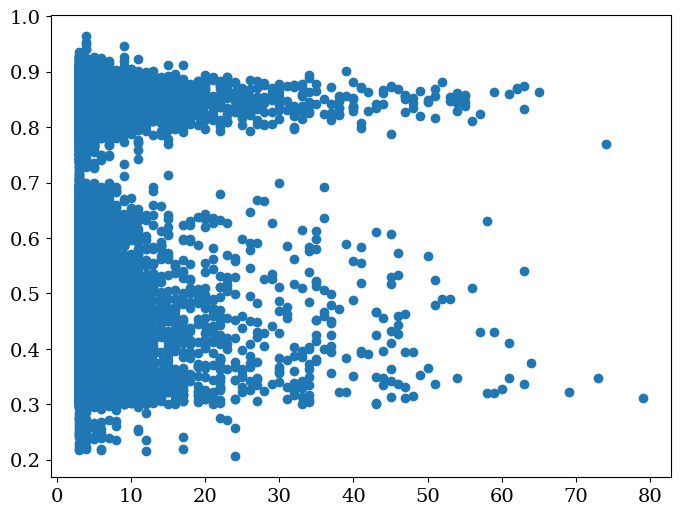

In [8]:
plt.scatter(
    chunk["node_degree"],
    chunk["tpr_mean"]
)

plt.show()

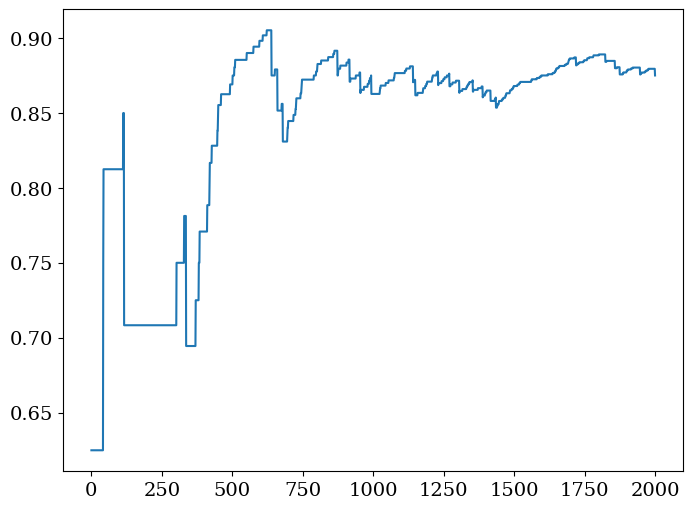

In [16]:
plt.plot(
    np.arange(2000),
    list(snap_df[(snap_df["node_id"]==4)&(snap_df["rep_id"]==1)]["tpr_mean"])[:2000])
plt.show()

In [125]:
snap_df[(snap_df["node_id"]==1)&(snap_df["rep_id"]==3)]

,rep_id,cascade_id,phase,node_id,true_mean,tpr_mean,fpr_mean,true_n,tpr_n,fpr_n,mean_trust,mean_trust_n,node_degree
1320000,3,1,burnin,1,0.482374,0.59674,0.418454,2.0,2.0,2.0,0.489207,2.591393,63
1320300,3,2,burnin,1,0.482374,0.59674,0.418454,2.0,2.0,2.0,0.489207,2.591393,63
1320600,3,3,burnin,1,0.482374,0.59674,0.418454,2.0,2.0,2.0,0.489207,2.591393,63
1320900,3,4,burnin,1,0.482374,0.59674,0.418454,2.0,2.0,2.0,0.489207,2.591393,63
1321200,3,5,burnin,1,0.482374,0.59674,0.418454,2.0,2.0,2.0,0.489207,2.591393,63
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1978500,3,2196,post,1,0.841285,0.59674,0.612303,1840.0,2.0,3.0,0.770608,31.607266,63
1978800,3,2197,post,1,0.841371,0.59674,0.612303,1841.0,2.0,3.0,0.770623,31.623139,63
1979100,3,2198,post,1,0.840915,0.59674,0.612303,1842.0,2.0,3.0,0.770440,31.639012,63
1979400,3,2199,post,1,0.841001,0.59674,0.612303,1843.0,2.0,3.0,0.770624,31.654885,63
